# Constraint Satisfaction Problem (CSP)

In questo notebook proverò a risolvere il problema di **Graph Coloring** (colorazione di un grafo) con diverse tecniche.
Ma prima: cos'è il **graph coloring**?

## Graph Coloring

Il **Graph Coloring** è un problema classico di informatica e ottimizzazione, classificato come Constraint Satisfaction Problem (**CSP**). Come ogni CSP, può essere definito tramite un insieme di variabili, un insieme di domini, un insieme di vincoli e un obiettivo (che per definizione è trovare un'assegnazione delle variabili che soddisfi tutti i vincoli insieme).
Nel nostro caso:

* **Variabili** ($V$): un insieme di vertici/nodi in un grafo $G = (V, E)$.
* **Domini** ($D$): un insieme di colori disponibili $C = \{c_1, c_2, \dots, c_k\}$ assegnato a ogni nodo.
* **Vincoli** ($C$): per ogni arco $(u, v) \in E$, il colore assegnato a $u$ non deve essere uguale al colore assegnato a $v$ ($\text{Color}(u) \neq \text{Color}(v)$).
* **Obiettivo**: assegnare un colore a ogni nodo in modo che due nodi adiacenti non condividano mai lo stesso colore, usando $k$ colori.

In [2]:
# 1. Installo networkx nel kernel del notebook corrente
%pip install "networkx>=3.4"

  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


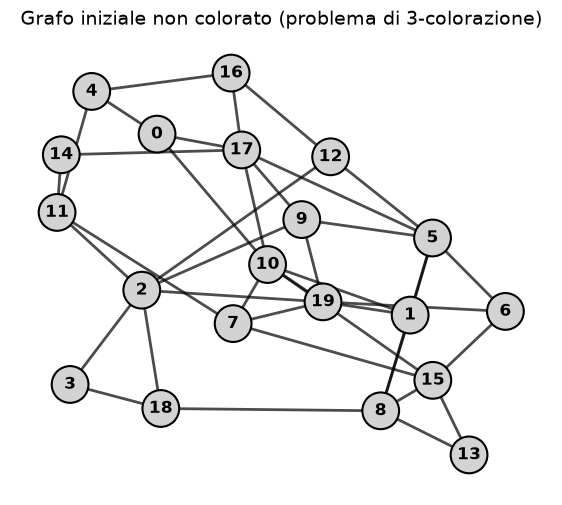

In [3]:
import networkx as nx  
import matplotlib.pyplot as plt

def draw_graph_state(G, color_map=None, title="Grafo non colorato", pos=None):
    """
    Disegna il grafo con i colori dei nodi indicati.

    Parametri:
    - G: grafo NetworkX
    - color_map: dict o lista di colori corrispondenti a ciascun nodo
    - title: titolo del grafico
    - pos: layout visivo fisso, per coerenza tra i frame
    """
    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(7, 6))

    if color_map is None:
        node_colors = ["#D3D3D3"] * len(G.nodes)
    elif isinstance(color_map, dict):
        node_colors = [color_map.get(node, "#D3D3D3") for node in G.nodes]
    else:
        node_colors = color_map

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=700, edgecolors="black", linewidths=1.5)
    nx.draw_networkx_edges(G, pos, width=2, alpha=0.7)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")

    plt.title(title, fontsize=14)
    plt.axis("off")
    plt.show()

# 1. Genero un grafo casuale G(n, p) con 20 nodi e probabilità 0.2 per lato
G = nx.fast_gnp_random_graph(n=20, p=0.2, seed=37)

# 2. Calcolo una volta sola la posizione dei nodi, così tutti i frame sono coerenti
pos = nx.forceatlas2_layout(G, seed=37)

# 3. Disegno lo stato iniziale, senza colori
draw_graph_state(G, title="Grafo iniziale non colorato (problema di 3-colorazione)", pos=pos)

## Backtracking

La prima cosa che voglio esplorare è il backtracking.

Il backtracking è l'algoritmo ricorsivo di base per risolvere i CSP. È essenzialmente una Depth-First Search (DFS) che sfrutta la struttura dei vincoli per evitare di esplorare cammini non validi.

Il funzionamento è abbastanza semplice:

1. Seleziona una variabile non assegnata e prova ad assegnarle un valore dal suo dominio.
2. Verifica se questa assegnazione viola qualche vincolo con le variabili già assegnate.
3. Se l'assegnazione è consistente, passa ricorsivamente alla variabile successiva.
4. Se un vincolo viene violato, oppure se si raggiunge un vicolo cieco (nessun colore/valore rimasto che non violi i vincoli), l'algoritmo fa backtracking (annulla l'ultima assegnazione) e prova un valore diverso per quella variabile.

In [4]:
def backtracing(G, color_palette):
    """
    Risolve il problema di graph coloring usando un DFS con backtracking standard.

    Parametri:
    - G: grafo NetworkX
    - color_palette: lista di colori disponibili (es. ['#ff9999', '#99ff99', '#9999ff'])

    Restituisce:
    - success: booleano che indica se è stata trovata una soluzione
    - final_assignment: dizionario che mappa nodi -> colori
    - history: lista di dict che registrano lo stato a ogni passo (per l'animazione)
    """
    nodes = list(G.nodes)
    history = []
    assignment = {}

    def is_valid(node, color):
        """Controlla se assegnare 'color' a 'node' viola qualche vincolo di adiacenza."""
        for neighbor in G.neighbors(node):
            if neighbor in assignment and assignment[neighbor] == color:
                return False
        return True

    def backtrack(node_idx):
        # 1. Registro lo stato corrente per l'animazione
        history.append(assignment.copy())

        # Caso base: tutti i nodi sono stati colorati con successo
        if node_idx == len(nodes):
            return True

        current_node = nodes[node_idx]

        # 2. Provo ciascun colore della palette
        for color in color_palette:
            if is_valid(current_node, color):
                assignment[current_node] = color

                # 3. Ricorsione sul nodo successivo
                if backtrack(node_idx + 1):
                    return True

                # 4. Backtracking: rimuovo il colore se porta a un vicolo cieco
                del assignment[current_node]

        return False

    success = backtrack(0)
    return success, assignment, history

Soluzione trovata? True
Passi totali per trovare la soluzione: 5331


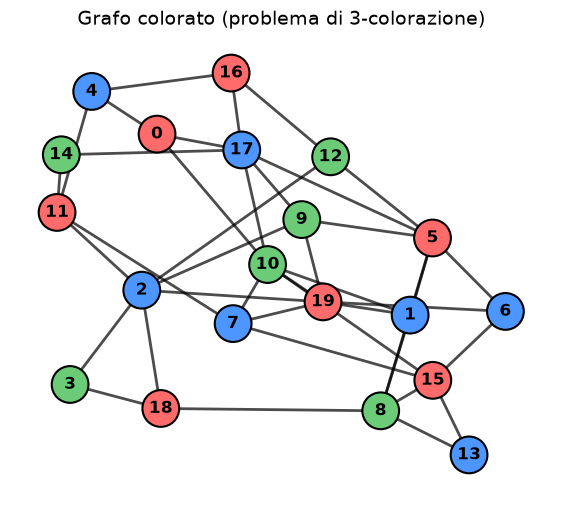

In [ ]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

# 1. Eseguo il backtracking
success, solution, history = backtracing(G, colors)

# 2. Stampo i risultati
print(f"Soluzione trovata? {success}")
print(f"Passi totali per trovare la soluzione: {len(history)}")

# 3. Disegno il grafo colorato
draw_graph_state(G, title="Grafo colorato (problema di 3-colorazione)", pos=pos, color_map=solution)

## Forward Checking

Passo poi all'implementazione del forward checking.

Il Forward Checking è un miglioramento del backtracking standard che introduce una forma di look-ahead per intercettare i fallimenti prima.

Funziona più o meno come il processo precedente, ma:

1. Ogni volta che a una variabile viene assegnato un valore, l'algoritmo "guarda avanti" a tutte le variabili non assegnate collegate da un vincolo.
2. Rimuove subito dai domini di quei vicini qualsiasi valore che entri in conflitto con il valore appena assegnato.
3. Se il dominio di un vicino non assegnato si riduce a vuoto (cioè restano 0 valori legali), il forward checking riconosce immediatamente che questo ramo fallirà e attiva il backtracking senza dover scendere ulteriormente nell'albero.

In [6]:
def forward_checking(G, color_palette):
    """
    Risolve il problema di graph coloring usando CSP con Forward Checking.

    Parametri:
    - G: grafo NetworkX
    - color_palette: lista di colori disponibili

    Restituisce:
    - success: booleano che indica se è stata trovata una soluzione
    - final_assignment: dizionario che mappa nodi -> colori
    - history: lista di dict che registrano lo stato a ogni passo (per l'animazione)
    """
    nodes = list(G.nodes)
    history = []

    # 1. Inizializzo i domini: ogni nodo parte con tutti i colori disponibili
    domains = {node: set(color_palette) for node in nodes}
    assignment = {}

    def backtrack(node_idx):
        # 1. Registro lo stato per la visualizzazione
        history.append(assignment.copy())

        # Caso base: tutti i nodi sono stati assegnati
        if node_idx == len(nodes):
            return True

        current_node = nodes[node_idx]

        # 2. Provo ciascun colore attualmente disponibile nel dominio del nodo
        # Uso list(domains[current_node]) per iterare sulle opzioni valide correnti
        for color in sorted(list(domains[current_node])):
            assignment[current_node] = color
            history.append(assignment.copy())

            # PASSO DI FORWARD CHECKING
            # Rimuovo questo colore dai domini di tutti i vicini non assegnati
            failure = False
            updated_domains = {}

            for neighbor in G.neighbors(current_node):
                if neighbor not in assignment:
                    if color in domains[neighbor]:
                        # Faccio una copia del dominio del vicino e rimuovo il colore
                        if neighbor not in updated_domains:
                            updated_domains[neighbor] = domains[neighbor].copy()
                        updated_domains[neighbor].remove(color)

                        # Se il dominio di un vicino si svuota, il forward check fallisce!
                        if len(updated_domains[neighbor]) == 0:
                            failure = True
                            break

            if not failure:
                # Applico temporaneamente gli aggiornamenti ai domini
                backup_domains = {}
                for neighbor, new_dom in updated_domains.items():
                    backup_domains[neighbor] = domains[neighbor]
                    domains[neighbor] = new_dom

                # 3. Ricorsione sul nodo successivo
                if backtrack(node_idx + 1):
                    return True

                # 4. Ripristino i domini dopo il fallimento della chiamata ricorsiva (Backtracking)
                for neighbor, old_dom in backup_domains.items():
                    domains[neighbor] = old_dom

            # 5. Rimuovo l'assegnazione del colore (Backtracking)
            del assignment[current_node]

        return False

    success = backtrack(0)
    return success, assignment, history

Soluzione trovata? True
Passi totali per trovare la soluzione: 873


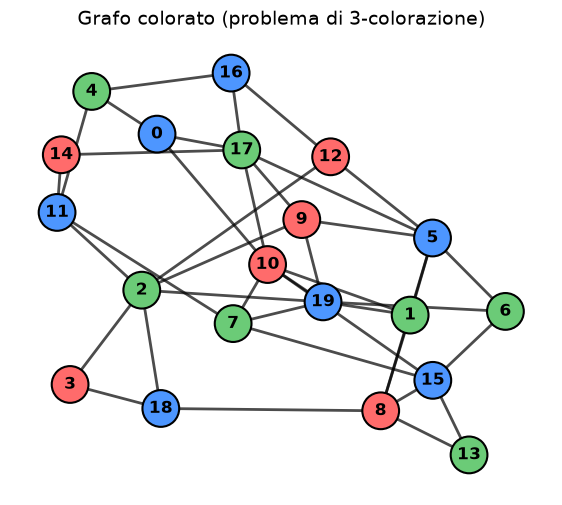

In [7]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

# 1. Eseguo il forward checking
success, solution, history = forward_checking(G, colors)

# 2. Stampo i risultati
print(f"Soluzione trovata? {success}")
print(f"Passi totali per trovare la soluzione: {len(history)}")
# 3. Disegno il grafo colorato
draw_graph_state(G, title="Grafo colorato (problema di 3-colorazione)", pos=pos, color_map=solution)

## AC-3

E posso finalmente procedere con l'implementazione della arc consistency (in particolare AC-3).

AC-3 è un potente algoritmo di propagazione dei vincoli. Mentre il forward checking aggiorna i domini solo dopo che è stata fatta una scelta, AC-3 viene di solito eseguito prima di iniziare la ricerca (o integrato durante di essa) per ridurre i domini il più possibile.

In particolare, definisco un "arco" come un vincolo diretto tra due variabili (es. la variabile $X$ deve essere consistente con la variabile $Y$). Un arco $(X, Y)$ è arc-consistent se per ogni valore nel dominio di $X$ esiste almeno un valore valido e non in conflitto nel dominio di $Y$.

Qui definisco l'algoritmo di propagazione dei vincoli AC-3.

1. L'algoritmo parte con una coda contenente tutti gli archi del grafo.
2. Estrae un arco $(X, Y)$ e controlla se ogni valore nel dominio di $X$ ha un valore di supporto nel dominio di $Y$.
3. Se un valore di $X$ non ha supporto, viene rimosso dal dominio di $X$.
4. Se qualche valore è stato rimosso da $X$, tutti gli archi vicini che puntano indietro a $X$ (come $(Z, X)$) vengono reinseriti nella coda, perché la loro consistenza potrebbe essere stata intaccata.

Il processo si ripete finché la coda non è vuota.

Più avanti userò AC-3 prima e durante l'algoritmo di backtracking per rendere l'albero di esplorazione banale da esplorare.

In particolare:

1. Inizializzo ogni nodo con tutti i colori disponibili.
2. Eseguo AC-3 per imporre l'arc consistency.
3. Seleziono un nodo non assegnato.
4. Provo un colore dal suo dominio.
5. Limito il dominio di quel nodo al solo colore scelto.
6. Eseguo AC-3 per propagare le conseguenze.
7. Ricorsione se consistente; altrimenti ripristino lo stato precedente e provo un altro colore.

Nota: in questa implementazione non uso alcuna euristica per l'esplorazione della coda.

In [8]:
def ac3(G, domains):
    """
    Esegue l'algoritmo AC-3 per imporre l'arc consistency sui domini del grafo.
    Restituisce False se qualche dominio diventa vuoto (inconsistente), altrimenti True.
    """
    # 1. Inizializzo la coda con tutti gli archi diretti (u, v) e (v, u)
    queue = []
    for u in G.nodes():
        for v in G.neighbors(u):
            queue.append((u, v))

    def revise(u, v):
        """Restringo il dominio di u eliminando i valori senza supporto in v."""
        revised = False
        to_remove = set()
        # Per ogni valore x in D(u), controllo se esiste un y in D(v) con y != x
        for x in domains[u]:
            if all(y == x for y in domains[v]):
                to_remove.add(x)
                revised = True
        if to_remove:
            domains[u] -= to_remove
        return revised

    while queue:
        u, v = queue.pop(0)
        if revise(u, v):
            if len(domains[u]) == 0:
                return False  # dominio svuotato, il problema è irrisolvibile con i domini correnti
            # Se il dominio di u è cambiato, devo ricontrollare tutti i vicini di u (tranne v)
            for w in G.neighbors(u):
                if w != v:
                    queue.append((w, u))

    return True


def solve_graph_coloring_ac3(G, color_palette):
    """
    Risolve il problema di graph coloring usando CSP con AC-3 (Maintaining Arc Consistency).

    Parametri:
    - G: grafo NetworkX
    - color_palette: lista di colori disponibili

    Restituisce:
    - success: booleano che indica se è stata trovata una soluzione
    - final_assignment: dizionario che mappa nodi -> colori
    - history: lista di dict che registrano lo stato a ogni passo (per l'animazione)
    """
    nodes = list(G.nodes)
    history = []

    # 1. Inizializzo i domini: ogni nodo parte con tutti i colori disponibili
    domains = {node: set(color_palette) for node in nodes}
    assignment = {}

    # 2. Preprocessing iniziale di arc consistency
    if not ac3(G, domains):
        return False, {}, []

    def backtrack(node_idx):
        history.append(assignment.copy())

        # Caso base: tutti i nodi sono stati assegnati
        if node_idx == len(nodes):
            return True

        current_node = nodes[node_idx]

        # 3. Provo ciascun colore attualmente disponibile nel dominio del nodo
        for color in sorted(list(domains[current_node])):
            # 4. Salvo lo stato corrente prima di provare questo ramo
            backup_assignment = assignment.copy()
            backup_domains = {n: dom.copy() for n, dom in domains.items()}

            # 5. Assegno il colore e restringo il dominio a solo quel colore
            assignment[current_node] = color
            domains[current_node] = {color}
            history.append(assignment.copy())

            # 6. Eseguo AC-3 per propagare i vincoli nella rete
            if ac3(G, domains):
                if backtrack(node_idx + 1):
                    return True

            # 7. In caso di fallimento, resetto lo stato al backup
            # Lo stesso vale per i domini
            assignment.clear()
            assignment.update(backup_assignment)

            domains.clear()
            domains.update(backup_domains)

        return False

    success = backtrack(0)
    return success, assignment, history

Soluzione trovata? True
Passi totali per trovare la soluzione: 49


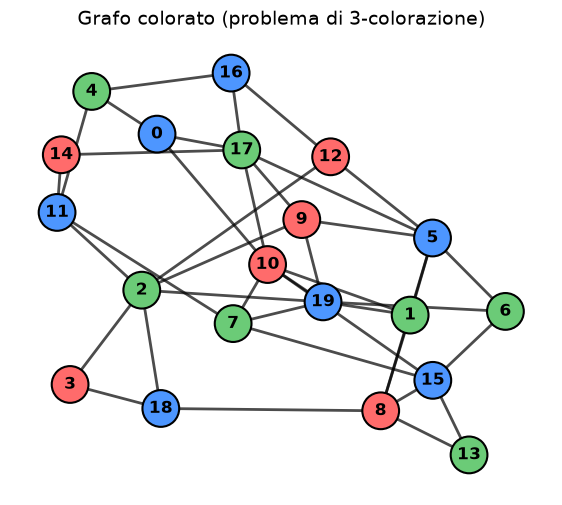

In [9]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

# 1. Eseguo la risoluzione con AC-3
success, solution, history = solve_graph_coloring_ac3(G, colors)

# 2. Stampo i risultati
print(f"Soluzione trovata? {success}")
print(f"Passi totali per trovare la soluzione: {len(history)}")
# 3. Disegno il grafo colorato
draw_graph_state(G, title="Grafo colorato (problema di 3-colorazione)", pos=pos, color_map=solution)

Qui aggiungo uno snippet di codice per visualizzare le assegnazioni esplorate durante la ricerca della soluzione.

Non è proprio il massimo per capire l'evoluzione delle restrizioni sui domini.

In [10]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display
import networkx as nx

def create_coloring_animation(G, history, pos=None, interval=200, filename="colormap.gif"):
    """
    Crea un'animazione matplotlib che mostra la cronologia della colorazione del grafo passo per passo.

    Parametri:
    - G: grafo NetworkX
    - history: lista di dict di assegnazione generati dal solver
    - pos: posizioni dei nodi per coerenza di layout
    - interval: tempo tra i frame in millisecondi (più basso = più veloce)

    Restituisce:
    - anim: oggetto FuncAnimation renderizzabile tramite HTML(anim.to_jshtml())
    """
    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    fig, ax = plt.subplots(figsize=(7, 6))

    def update(frame):
        ax.clear()
        assignment = history[frame]

        # 1. Costruisco la lista dei colori dei nodi in base allo stato corrente
        node_colors = []
        for node in G.nodes():
            if node in assignment:
                node_colors.append(assignment[node])
            else:
                node_colors.append("#D3D3D3")  # grigio chiaro di default per i nodi non colorati

        # 2. Disegno lo stato del grafo per questo frame
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=700, edgecolors="black", linewidths=1.5)
        nx.draw_networkx_edges(G, pos, ax=ax, width=2, alpha=0.7)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=12, font_weight="bold")

        ax.set_title(f"Passo {frame + 1} di {len(history)}", fontsize=14, fontweight="bold")
        ax.axis("off")

    # 3. Creo l'animazione
    anim = animation.FuncAnimation(fig, update, frames=len(history), interval=interval, repeat=True)

    # 4. Chiudo la figura sottostante per non mostrare un duplicato statico sotto
    plt.close(fig)

    # 5. Salvo l'animazione come GIF
    anim.save(filename, writer='pillow', fps=1)
    plt.close(fig)

    # 6. La combino con display()
    return HTML(f'<img src="{filename}" alt="Animazione del puzzle">')

In [11]:
# 1. Genero l'oggetto animazione (es. usando la history di AC-3 o del Forward Checking)
anim = create_coloring_animation(G, history, pos=pos, interval=150)

# 2. Visualizzo l'animazione
display(anim)